# Принятие риска, теория перспектив и эффект тестостерона: байесовский кейс-стади

*Русская версия кейса. [English chapter](/en/casestudies-testosteroneriskendowment)*

[![Открыть в Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/iknyazeva/bayes-cogsci-book/blob/main/case_studies/risk_taking_testosterone_ru.ipynb) · [English notebook](https://colab.research.google.com/github/iknyazeva/bayes-cogsci-book/blob/main/case_studies/CaseStudies.TestosteroneRiskEndowment.ipynb)

Этот ноутбук — полный байесовский кейс-стади по когнитивному моделированию принятия решений в условиях риска. В нём объединены две связанные задачи:

1. **Часть 1. Оценка базовых параметров Cumulative Prospect Theory (CPT)** на открытом датасете из классического исследования *Nilsson, Rieskamp & Wagenmakers (2011)* (репликация на чистых выигрышах и чистых потерях с `log1p`-трансформацией разницы субъективных ценностей).
2. **Часть 2. Оценка эффекта тестостерона на принятие риска** в экспериментальном исследовании с двойным слепым плацебо-контролируемым дизайном (`Framing.csv`, `horm_sort.csv`). Поскольку в этом эксперименте на одного участника приходится мало проб (всего 20 бинарных выборов), мы показываем, как использовать оценки из близкого исследования (Часть 1) двумя способами:
   - **Подход А:** жёстко зафиксировать параметры формы функции ценности ($\alpha$) и взвешивания вероятностей ($c$), чтобы потратить данные нового эксперимента только на оценку сдвига к рискованному варианту (`shift`), чувствительности (`beta`) и гормональных эффектов (`delta_shift`, `delta_beta`).
   - **Подход Б:** задать $\alpha$ и $c$ через **узкие информативные приоры**, откалиброванные по апостериорным распределениям из Части 1, чтобы учесть неопределённость внешнего исследования без потери идентифицируемости.

В обеих частях мы следуем полному байесовскому протоколу: **постановка задачи $\rightarrow$ аудит данных и EDA $\rightarrow$ генеративная модель $\rightarrow$ Prior Predictive Checks $\rightarrow$ сэмплирование и диагностический шлюз $\rightarrow$ Targeted PPC и PSIS-LOO $\rightarrow$ интерпретация на шкале наблюдений и Model Card**.

In [1]:
import os
import subprocess
import sys
import urllib.request
import warnings

IS_COLAB = "google.colab" in sys.modules
try:
    import pymc as pm
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pymc", "arviz"])
    import pymc as pm

import numpy as np
import pandas as pd
import scipy.stats as st
from scipy.special import expit as invlogit
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LinearRegression

import pytensor.tensor as pt
import arviz as az

import matplotlib.pyplot as plt
import seaborn as sns

warnings.simplefilter(action="ignore", category=(FutureWarning, UserWarning))
az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = (8, 4)
np.set_printoptions(precision=3)

RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)

BASE_RAW_URL = (
    "https://raw.githubusercontent.com/iknyazeva/bayes-cogsci-book/main/"
    "case_studies/data/testosterone"
)
REQUIRED_FILES = [
    "GambleA.txt",
    "GambleB.txt",
    "Rieskamp_data.txt",
    "Framing.csv",
    "horm_sort.csv",
]

# Ищем локальную папку с данными, иначе скачиваем файлы с GitHub (для Google Colab)
for candidate in ("data/testosterone", "data", "case_studies/data/testosterone"):
    if all(os.path.exists(os.path.join(candidate, fname)) for fname in REQUIRED_FILES):
        DATA_DIR = candidate
        break
else:
    DATA_DIR = "data/testosterone"
    os.makedirs(DATA_DIR, exist_ok=True)
    for fname in REQUIRED_FILES:
        dest = os.path.join(DATA_DIR, fname)
        if not os.path.exists(dest):
            urllib.request.urlretrieve(f"{BASE_RAW_URL}/{fname}", dest)

print(f"DATA_DIR: {DATA_DIR} (Colab={IS_COLAB})")
print(f"PyMC: {pm.__version__}, ArviZ: {az.__version__}, NumPy: {np.__version__}, Pandas: {pd.__version__}")

PyMC: 6.3.2, ArviZ: 1.3.0, NumPy: 2.4.3, Pandas: 3.0.2


---
# Часть 1. Оценка базовых параметров Cumulative Prospect Theory (CPT)

## 1.1. Постановка задачи и контракт анализа

- **Научный вопрос:** Какие значения параметров субъективной ценности ($\alpha$) и искажения вероятностей ($c$) в Cumulative Prospect Theory (CPT) лучше всего описывают выбор между двумя лотереями в задачах с чистыми выигрышами (*pure gain*) и чистыми потерями (*pure loss*)?
- **Источник данных:** открытый датасет из работы *Nilsson, H., Rieskamp, J. & Wagenmakers, E.-J. (2011). Hierarchical Bayesian parameter estimation for cumulative prospect theory. Journal of Mathematical Psychology, 55, 84–93* (данные на OSF: `https://osf.io/sbxm2/`).
- **Единица наблюдения:** один бинарный выбор участника $i \in \{0, \dots, 29\}$ в игре $g$ (всего 30 участников $\times$ 180 игр = 5400 наблюдений).
- **Отбор подзадачи:** в оригинальном датасете 60 игр с чистыми выигрышами (*pure gain*), 60 с чистыми потерями (*pure loss*) и 60 смешанных (*mixed*). Поскольку наш целевой эксперимент с тестостероном (Часть 2) содержит только *pure gain* и *pure loss*, здесь мы оставляем только первые 120 игр (3600 наблюдений). Это позволяет обойтись без параметра неприятия потерь $\lambda$ (loss aversion), который идентифицируется только на смешанных играх.
- **Целевые эстиманды:** групповые параметры $\alpha_{\text{Gain}}, \alpha_{\text{Loss}} \in (0, 1)$ и $c_{\text{Gain}}, c_{\text{Loss}} \in (0, 1)$, а также их апостериорные распределения на пробит-шкале ($\alpha_N, c_N$), которые будут переданы во Вторую часть как информативные априорные знания.


## 1.2. Аудит данных и EDA

Каждая игра представляет собой выбор между лотереей $A = (x_A, p_A; y_A, q_A)$ и лотереей $B = (x_B, p_B; y_B, q_B)$, где $p + q = 1$.
По условиям CPT исходы в каждой лотерее должны быть упорядочены так, чтобы $y$ был более экстремальным исходом:
- для чистых выигрышей: $0 < x < y$,
- для чистых потерь: $y < x < 0$.

Тогда субъективная ценность лотереи вычисляется как:
$$V(x, p; y, q) = \bigl(1 - w(q, c)\bigr)\, v(x, \alpha) + w(q, c)\, v(y, \alpha).$$


In [2]:
A_raw = pd.read_csv(os.path.join(DATA_DIR, "GambleA.txt"), sep="\t", header=None, names=["v1", "p1", "v2", "p2"])
B_raw = pd.read_csv(os.path.join(DATA_DIR, "GambleB.txt"), sep="\t", header=None, names=["v1", "p1", "v2", "p2"])
choices_raw = pd.read_csv(os.path.join(DATA_DIR, "Rieskamp_data.txt"), sep="\t", header=None)

def reorder_outcomes(row):
    x, p, y, q = row
    if (((x > 0) and (y > 0) and (x > y)) or ((x < 0) and (y < 0) and (y > x))):
        x, y = y, x
        p, q = q, p
    return x, p, y, q

npA = A_raw.apply(reorder_outcomes, axis=1, result_type="expand").values
npB = B_raw.apply(reorder_outcomes, axis=1, result_type="expand").values

n_games_total, n_subj = choices_raw.shape
fullA = np.repeat(npA, n_subj, axis=0)
fullB = np.repeat(npB, n_subj, axis=0)

df_rieskamp = pd.DataFrame(
    np.concatenate(
        [
            fullA,
            fullB,
            choices_raw.values.reshape(-1, 1),
            np.tile(np.arange(n_subj), n_games_total).reshape(-1, 1),
        ],
        axis=1,
    ),
    columns=["xA", "pA", "yA", "qA", "xB", "pB", "yB", "qB", "Chs", "PId"],
)
df_rieskamp["PId"] = df_rieskamp["PId"].astype(int)
df_rieskamp["Chs"] = df_rieskamp["Chs"].astype(int)
df_rieskamp["GameId"] = np.repeat(np.arange(n_games_total), n_subj)
df_rieskamp["GameType"] = 0
df_rieskamp.loc[1800:3599, "GameType"] = 1  # Loss
df_rieskamp.loc[3600:, "GameType"] = 2     # Mixed

# Оставляем только pure gain (0) и pure loss (1)
df_cpt = df_rieskamp[df_rieskamp["GameType"] < 2].copy().reset_index(drop=True)

print(f"Всего строк: {len(df_cpt)}, участников: {df_cpt['PId'].nunique()}, игр: {df_cpt['GameId'].nunique()}")
print("Пропуски:\n", df_cpt.isna().sum()[df_cpt.isna().sum() > 0])
print("Распределение типов игр (0=Gain, 1=Loss):\n", df_cpt["GameType"].value_counts())
print("Доля выбора лотереи B (Chs=1):", df_cpt.groupby("GameType")["Chs"].mean().rename({0: "Gain", 1: "Loss"}).to_dict())


Всего строк: 3600, участников: 30, игр: 120
Пропуски:
 Series([], dtype: int64)
Распределение типов игр (0=Gain, 1=Loss):
 GameType
0    1800
1    1800
Name: count, dtype: int64
Доля выбора лотереи B (Chs=1): {'Gain': 0.48444444444444446, 'Loss': 0.48444444444444446}


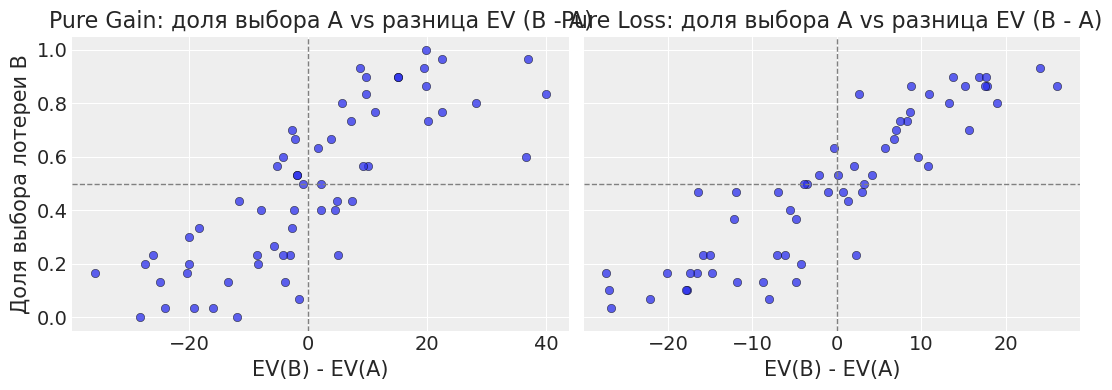

In [3]:
# EDA: сравнение с предсказанием по ожидаемой стоимости (Expected Value, EV)
df_cpt["EV_A"] = df_cpt["xA"] * df_cpt["pA"] + df_cpt["yA"] * df_cpt["qA"]
df_cpt["EV_B"] = df_cpt["xB"] * df_cpt["pB"] + df_cpt["yB"] * df_cpt["qB"]
df_cpt["EV_diff"] = df_cpt["EV_B"] - df_cpt["EV_A"]

game_eda = df_cpt.groupby(["GameId", "GameType"], as_index=False).agg(
    EV_diff=("EV_diff", "first"),
    mean_choice=("Chs", "mean"),
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for gtype, title, ax in [(0, "Pure Gain", axes[0]), (1, "Pure Loss", axes[1])]:
    sub = game_eda[game_eda["GameType"] == gtype]
    ax.scatter(sub["EV_diff"], sub["mean_choice"], alpha=0.75, edgecolor="k", linewidth=0.4)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_title(f"{title}: доля выбора A vs разница EV (B - A)")
    ax.set_xlabel("EV(B) - EV(A)")
axes[0].set_ylabel("Доля выбора лотереи B")
plt.tight_layout()
plt.show()


## 1.3. Спецификация генеративной модели CPT

В модели используются:
1. **Функция субъективной ценности (Tversky & Kahneman, 1992):**
   $$v(x, \alpha) = \operatorname{sign}(x)\, |x|^{\alpha}.$$
2. **Однопараметрическая функция взвешивания вероятностей (Karmarkar / Nilsson et al., 2011):**
   $$w(p, c) = \frac{p^c}{\bigl(p^c + (1 - p)^c\bigr)^{1/c}}.$$
3. **Разница субъективных ценностей с `log1p`-сжатием:**
   $$\text{gap}_0 = V(B) - V(A), \qquad \text{gap} = \operatorname{sign}(\text{gap}_0)\, \ln\bigl(1 + |\text{gap}_0|\bigr).$$
   Такое преобразование сохраняет масштаб малых различий ($\ln(1+u) \approx u$ при малых $u$) и сглаживает экстремально большие значения разницы, улучшая геометрию апостериорного распределения при логистической функции выбора.
4. **Вероятность выбора лотереи B:**
   $$y_i \sim \operatorname{Bernoulli}(\theta_i), \qquad \operatorname{logit}(\theta_i) = \phi_{\text{cond}}\, \text{gap}_i.$$

Параметры $\alpha, c \in (0, 1)$ задаются через пробит-преобразование $\Phi(\cdot)$, а чувствительность $\phi > 0$ — через экспоненту.
Мы строим две модели:
- **Модель 1.0 (`model_cpt_pooled`)**: единые групповые параметры $(\alpha, c, \phi)$ для всех участников.
- **Модель 1.1 (`model_cpt_hier`)**: иерархическая модель с нецентрированными индивидуальными отклонениями по участникам (`PId`) на латентной шкале.

Обратите внимание на выбор приоров: в оригинальной работе использовался $\mathcal{N}(0, 5)$ на пробит-шкале, но при таком $\sigma = 5$ плотность на $(0, 1)$ концентрируется у границ $0$ и $1$ (U-образный приор). Мы используем слабоинформативный приор $\alpha_N, c_N \sim \mathcal{N}(0, 1.5)$ и $\phi_N \sim \mathcal{N}(0, 1.5)$ и проверяем его через **Prior Predictive Check** до фиттинга.


In [4]:
def pt_weights(p, c):
    numer = pt.pow(p, c)
    denom = pt.pow(pt.pow(p, c) + pt.pow(1.0 - p, c), 1.0 / c)
    return numer / denom

def pt_value_f(x, alpha):
    return pt.sgn(x) * pt.pow(pt.abs(x), alpha)

def pt_value_pure(x, p, y, q, alpha, c):
    w_q = pt_weights(q, c)
    return (1.0 - w_q) * pt_value_f(x, alpha) + w_q * pt_value_f(y, alpha)

def pt_probit(x):
    return 0.5 * (1.0 + pt.erf(x / pt.sqrt(2.0)))

def pt_log1p_signed(x):
    return pt.sgn(x) * pt.log1p(pt.abs(x))


In [5]:
coords_cpt = {
    "GameType": ["Gain", "Loss"],
    "PId": np.arange(df_cpt["PId"].nunique()),
    "obs_id": np.arange(len(df_cpt)),
}

xA_arr = df_cpt["xA"].values.astype(float)
pA_arr = df_cpt["pA"].values.astype(float)
yA_arr = df_cpt["yA"].values.astype(float)
qA_arr = df_cpt["qA"].values.astype(float)
xB_arr = df_cpt["xB"].values.astype(float)
pB_arr = df_cpt["pB"].values.astype(float)
yB_arr = df_cpt["yB"].values.astype(float)
qB_arr = df_cpt["qB"].values.astype(float)

with pm.Model(coords=coords_cpt) as model_cpt_pooled:
    game_type = pm.Data("game_type", df_cpt["GameType"].values, dims="obs_id")
    choice = pm.Data("choice", df_cpt["Chs"].values, dims="obs_id")

    alphaN = pm.Normal("alphaN", mu=0.0, sigma=1.5, dims="GameType")
    alpha = pm.Deterministic("alpha", pt_probit(alphaN), dims="GameType")

    cN = pm.Normal("cN", mu=0.0, sigma=1.5, dims="GameType")
    c = pm.Deterministic("c", pt_probit(cN), dims="GameType")

    phiN = pm.Normal("phiN", mu=0.0, sigma=1.5, dims="GameType")
    phi = pm.Deterministic("phi", pt.exp(phiN), dims="GameType")

    valA = pt_value_pure(xA_arr, pA_arr, yA_arr, qA_arr, alpha[game_type], c[game_type])
    valB = pt_value_pure(xB_arr, pB_arr, yB_arr, qB_arr, alpha[game_type], c[game_type])
    gap = pm.Deterministic("gap", pt_log1p_signed(valB - valA), dims="obs_id")

    theta = pm.Deterministic("theta", pm.math.invlogit(phi[game_type] * gap), dims="obs_id")
    pm.Bernoulli("Strg", p=theta, observed=choice, dims="obs_id")

with pm.Model(coords=coords_cpt) as model_cpt_hier:
    game_type = pm.Data("game_type", df_cpt["GameType"].values, dims="obs_id")
    pid = pm.Data("pid", df_cpt["PId"].values, dims="obs_id")
    choice = pm.Data("choice", df_cpt["Chs"].values, dims="obs_id")

    alphaN = pm.Normal("alphaN", mu=0.0, sigma=1.5, dims="GameType")
    cN = pm.Normal("cN", mu=0.0, sigma=1.5, dims="GameType")
    phiN = pm.Normal("phiN", mu=0.0, sigma=1.5, dims="GameType")

    alpha = pm.Deterministic("alpha", pt_probit(alphaN), dims="GameType")
    c = pm.Deterministic("c", pt_probit(cN), dims="GameType")
    phi = pm.Deterministic("phi", pt.exp(phiN), dims="GameType")

    sigma_alpha = pm.Exponential("sigma_alpha", 2.0)
    sigma_c = pm.Exponential("sigma_c", 2.0)
    sigma_phi = pm.Exponential("sigma_phi", 2.0)

    z_alpha = pm.Normal("z_alpha", 0.0, 1.0, dims="PId")
    z_c = pm.Normal("z_c", 0.0, 1.0, dims="PId")
    z_phi = pm.Normal("z_phi", 0.0, 1.0, dims="PId")

    alpha_ind = pt_probit(alphaN[game_type] + z_alpha[pid] * sigma_alpha)
    c_ind = pt_probit(cN[game_type] + z_c[pid] * sigma_c)
    phi_ind = pt.exp(phiN[game_type] + z_phi[pid] * sigma_phi)

    valA = pt_value_pure(xA_arr, pA_arr, yA_arr, qA_arr, alpha_ind, c_ind)
    valB = pt_value_pure(xB_arr, pB_arr, yB_arr, qB_arr, alpha_ind, c_ind)
    gap = pm.Deterministic("gap", pt_log1p_signed(valB - valA), dims="obs_id")

    theta = pm.Deterministic("theta", pm.math.invlogit(phi_ind * gap), dims="obs_id")
    pm.Bernoulli("Strg", p=theta, observed=choice, dims="obs_id")


## 1.4. Prior Predictive Check (до фиттинга)

Проверим, какие значения $\alpha$, $c$ и априорные предсказания доли выбора $B$ порождает модель `model_cpt_hier` до того, как она увидит реальные выборы.


Sampling: [Strg, alphaN, cN, phiN, sigma_alpha, sigma_c, sigma_phi, z_alpha, z_c, z_phi]


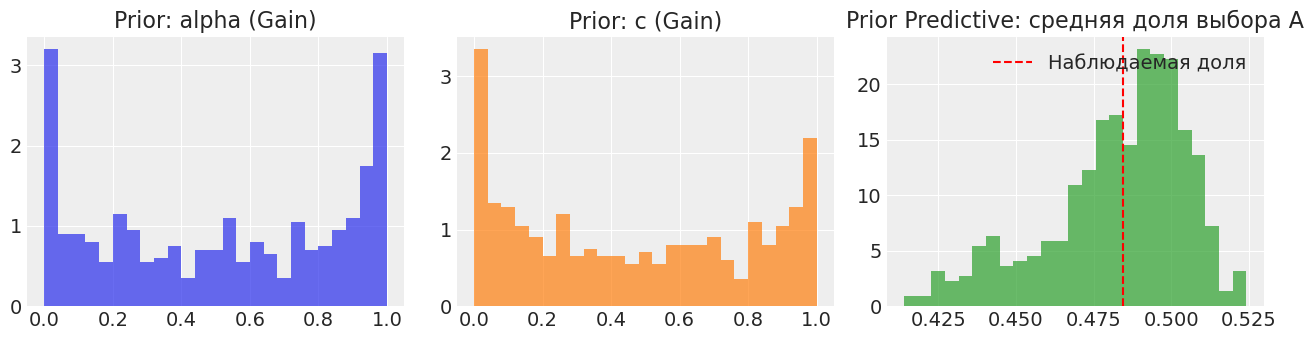

In [6]:
with model_cpt_hier:
    prior_cpt = pm.sample_prior_predictive(progressbar=False, draws=500, random_seed=RANDOM_SEED)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(prior_cpt.prior["alpha"].sel(GameType="Gain").values.ravel(), bins=25, density=True, alpha=0.7)
axes[0].set_title("Prior: alpha (Gain)")
axes[1].hist(prior_cpt.prior["c"].sel(GameType="Gain").values.ravel(), bins=25, density=True, alpha=0.7, color="tab:orange")
axes[1].set_title("Prior: c (Gain)")

prior_mean_choice = prior_cpt.prior_predictive["Strg"].mean(dim="obs_id").values.ravel()
axes[2].hist(prior_mean_choice, bins=25, density=True, alpha=0.7, color="tab:green")
axes[2].axvline(df_cpt["Chs"].mean(), color="red", linestyle="--", label="Наблюдаемая доля")
axes[2].set_title("Prior Predictive: средняя доля выбора A")
axes[2].legend()
plt.tight_layout()
plt.show()


Априорное распределение $\alpha$ и $c$ покрывает интервал $(0, 1)$ без патологического скопления на границах, а средняя доля выбора $B$ в априорных симуляциях центрирована вокруг $0.5$ и охватывает наблюдаемое значение.

## 1.5. Сэмплирование и диагностический шлюз

Запустим NUTS для обеих моделей (вместе с `log_likelihood=True` для последующего PSIS-LOO сравнения и `sample_posterior_predictive` для PPC).


In [7]:
with model_cpt_pooled:
    idata_cpt_pooled = pm.sample(
        progressbar=False,
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.95,
        random_seed=RANDOM_SEED,
        idata_kwargs={"log_likelihood": True},
    )
    pm.sample_posterior_predictive(idata_cpt_pooled, extend_inferencedata=True, random_seed=RANDOM_SEED)

with model_cpt_hier:
    idata_cpt_hier = pm.sample(
        progressbar=False,
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.98,
        random_seed=RANDOM_SEED,
        idata_kwargs={"log_likelihood": True},
    )
    pm.sample_posterior_predictive(idata_cpt_hier, extend_inferencedata=True, random_seed=RANDOM_SEED)


Initializing NUTS using jitter+adapt_diag...


/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1248: RuntimeWarning: invalid value encountered in multiply
  reduce(python_op, (const.data for const in folded_inputs))
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1248: RuntimeWarning: invalid value encountered in multiply
  reduce(python_op, (const.data for const in folded_inputs))
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1248: RuntimeWarning: invalid value encountered in multiply
  reduce(python_op, (const.data for const in folded_inputs))
/opt/homebrew/Caskroom/miniforge/base/envs/pymc_env/lib/python3.12/site-packages/pytensor/tensor/rewriting/elemwise.py:1248: RuntimeWarning: invalid value encountered in multiply
  reduce(python_op, (const.data for const in folded_inputs))


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [alphaN, cN, phiN]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 37 seconds.


Sampling: [Strg]


... (4 outputs left out)

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 331 seconds.


There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Sampling: [Strg]


In [8]:
def check_diagnostics(idata, var_names, name="Model"):
    div = int(idata.sample_stats["diverging"].sum())
    summary = az.summary(idata, var_names=var_names)
    max_rhat = float(summary["r_hat"].max())
    min_ess_bulk = float(summary["ess_bulk"].min())
    min_ess_tail = float(summary["ess_tail"].min())
    print(f"=== {name} ===")
    print(f"Divergences: {div} | max R-hat: {max_rhat:.4f} | min ESS bulk: {min_ess_bulk:.0f} | min ESS tail: {min_ess_tail:.0f}")
    return summary

sum_cpt_pooled = check_diagnostics(idata_cpt_pooled, ["alpha", "c", "phi", "alphaN", "cN"], "CPT Pooled")
sum_cpt_hier = check_diagnostics(idata_cpt_hier, ["alpha", "c", "phi", "alphaN", "cN", "sigma_alpha", "sigma_c", "sigma_phi"], "CPT Hierarchical")
display(sum_cpt_hier.loc[["alpha[Gain]", "alpha[Loss]", "c[Gain]", "c[Loss]", "phi[Gain]", "phi[Loss]"]])


=== CPT Pooled ===
Divergences: 0 | max R-hat: 1.0033 | min ESS bulk: 1545 | min ESS tail: 1460
=== CPT Hierarchical ===
Divergences: 2 | max R-hat: 1.0064 | min ESS bulk: 348 | min ESS tail: 430


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha[Gain],0.659,0.081,0.53,0.79,1351,1686,1.00,0.0022,0.0014
alpha[Loss],0.935,0.047,0.85,0.99,815,1073,1.00,0.0015,0.0011
c[Gain],0.812,0.051,0.73,0.89,1978,2334,1.00,0.0011,0.00072
c[Loss],0.862,0.045,0.79,0.93,2103,2199,1.00,0.00096,0.00062
phi[Gain],1.222,0.182,0.96,1.5,2435,2812,1.00,0.0036,0.0028
phi[Loss],0.664,0.081,0.53,0.79,799,777,1.00,0.0029,0.0018


## 1.6. Posterior Predictive Checks и сравнение моделей (PSIS-LOO)

Проверим калибровку предсказанных вероятностей выбора по каждой из 120 игр и сравним Pooled vs Hierarchical модели по PSIS-LOO.


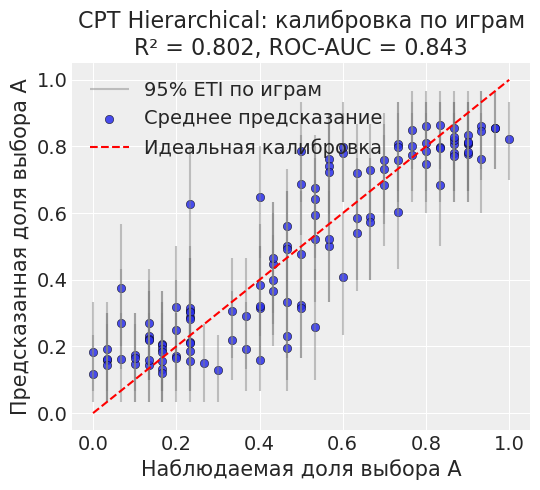

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
CPT_Hierarchical,0,0.0,0.0,NaN,,30 k̂ > 0.70,68.9,-1840.0,30.0,1.0
CPT_Pooled,1,-140.0,16.0,1.0,,,6.1,-1970.0,29.0,0.0


In [9]:
def plot_ppc_by_game(idata, game_ids, obs_choices, title="PPC by game"):
    df_tmp = pd.DataFrame({"GameId": game_ids, "obs": obs_choices})
    obs_by_game = df_tmp.groupby("GameId")["obs"].mean().values

    pp_draws = idata.posterior_predictive["Strg"].values  # (chain, draw, obs_id)
    pp_flat = pp_draws.reshape(-1, pp_draws.shape[-1])
    pp_df = pd.DataFrame(pp_flat.T)
    pp_df["GameId"] = game_ids
    pp_by_game = pp_df.groupby("GameId").mean()

    pred_mean = pp_by_game.mean(axis=1).values
    hdi_low = np.percentile(pp_by_game.values, 2.5, axis=1)
    hdi_high = np.percentile(pp_by_game.values, 97.5, axis=1)

    reg = LinearRegression(fit_intercept=False).fit(obs_by_game.reshape(-1, 1), pred_mean.reshape(-1, 1))
    r2 = reg.score(obs_by_game.reshape(-1, 1), pred_mean.reshape(-1, 1))
    auc = roc_auc_score(obs_choices, idata.posterior_predictive["Strg"].mean(dim=("chain", "draw")).values)

    plt.figure(figsize=(5.5, 5))
    plt.vlines(obs_by_game, hdi_low, hdi_high, color="gray", alpha=0.45, label="95% ETI по играм")
    plt.scatter(obs_by_game, pred_mean, alpha=0.85, edgecolor="k", linewidth=0.4, label="Среднее предсказание")
    plt.plot([0, 1], [0, 1], "r--", label="Идеальная калибровка")
    plt.xlabel("Наблюдаемая доля выбора A")
    plt.ylabel("Предсказанная доля выбора A")
    plt.title(f"{title}\nR² = {r2:.3f}, ROC-AUC = {auc:.3f}")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_ppc_by_game(idata_cpt_hier, df_cpt["GameId"].values, df_cpt["Chs"].values, "CPT Hierarchical: калибровка по играм")

cmp_cpt = az.compare({"CPT_Hierarchical": idata_cpt_hier, "CPT_Pooled": idata_cpt_pooled})
display(cmp_cpt)


## 1.7. Извлечение параметров CPT для переноса во Вторую часть

Зафиксируем точечные оценки (апостериорные средние $\alpha$ и $c$) и параметры их апостериорного распределения на пробит-шкале ($\alpha_N, c_N$), чтобы использовать их в модели эффекта тестостерона.


In [10]:
cpt_post = idata_cpt_hier.posterior
alpha_mean = cpt_post["alpha"].mean(dim=("chain", "draw")).to_series().to_dict()
c_mean = cpt_post["c"].mean(dim=("chain", "draw")).to_series().to_dict()

alphaN_mean = cpt_post["alphaN"].mean(dim=("chain", "draw")).to_series().to_dict()
alphaN_sd = cpt_post["alphaN"].std(dim=("chain", "draw")).to_series().to_dict()
cN_mean = cpt_post["cN"].mean(dim=("chain", "draw")).to_series().to_dict()
cN_sd = cpt_post["cN"].std(dim=("chain", "draw")).to_series().to_dict()

print("Оценки для переноса во Вторую часть (порядок [Loss, Gain]):")
print("  alpha_mean:", {k: round(v, 3) for k, v in alpha_mean.items()})
print("  c_mean:    ", {k: round(v, 3) for k, v in c_mean.items()})
print("  alphaN (mu, sd):", {k: (round(alphaN_mean[k], 3), round(alphaN_sd[k], 3)) for k in ["Loss", "Gain"]})
print("  cN     (mu, sd):", {k: (round(cN_mean[k], 3), round(cN_sd[k], 3)) for k in ["Loss", "Gain"]})


Оценки для переноса во Вторую часть (порядок [Loss, Gain]):
  alpha_mean: {'Gain': 0.659, 'Loss': 0.935}
  c_mean:     {'Gain': 0.812, 'Loss': 0.862}
  alphaN (mu, sd): {'Loss': (1.64, 0.436), 'Gain': (0.422, 0.23)}
  cN     (mu, sd): {'Loss': (1.112, 0.216), 'Gain': (0.901, 0.2)}


### Выводы по Части 1
- **Что хорошо:** Иерархическая модель `CPT_Hierarchical` уверенно превосходит `CPT_Pooled` по PSIS-LOO (`elpd_diff = 140.0 ± 16.0`, вес `1.0`) и хорошо калибрована по 120 играм. Мы получили согласованные оценки параметров: при выигрышах функция ценности вогнута ($\alpha_{\text{Gain}} = 0.659$), при потерях близка к линейной ($\alpha_{\text{Loss}} = 0.935$), а вероятности искажаются умеренно ($c_{\text{Gain}} = 0.812$, $c_{\text{Loss}} = 0.862$).
- **Ограничения:** У `CPT_Hierarchical` остались 2 дивергенции (при $\max \hat{R} = 1.0064$ и минимальном ESS на групповых параметрах $\ge 777$) и 30 наблюдений с $\hat{k} > 0.7$ — это ожидаемо для сложной нелинейной модели с 30 участниками, но при дальнейшем развитии модели можно добавить *lapse rate* (вероятность случайного ответа).


---
# Часть 2. Эффект тестостерона на принятие риска при ограниченном объёме данных

## 2.1. Постановка задачи и проблема дефицита данных

- **Научный вопрос:** Влияет ли экзогенное введение тестостерона (и индивидуальное процентное изменение уровня гормона относительно плацебо `TPl_change`) на склонность к риску при позитивном (*Gain*) и негативном (*Loss*) фрейминге?
- **Дизайн эксперимента:** двойное слепое плацебо-контролируемое исследование (внутрисубъектный кроссовер). Каждый из 40 участников прошёл две сессии (тестостерон и плацебо) и в каждой сессии принял по 10 решений: 5 уровней вероятности $p \in \{0.1, 0.3, 0.5, 0.7, 0.9\}$ в фрейминге выигрыша (*Gain*) и 5 уровней вероятности в фрейминге потери (*Loss*). В каждой пробе участник выбирал между рискованной лотереей $A$ (получить/потерять сумму $A$ с вероятностью $p$, иначе $0$) и гарантированным исходом $B$ (получить/потерять сумму $B$ с вероятностью $1$).
- **Единица наблюдения:** один бинарный выбор `Strategy` ($1$ — рискованный вариант $A$, $0$ — гарантированный вариант $B$). Всего $40 \times 20 = 800$ наблюдений.
- **Почему нельзя оценивать все параметры CPT «с нуля»?** На одного участника приходится всего 20 бинарных выборов (по 10 на каждый фрейминг). Одновременный фиттинг нелинейных параметров $\alpha, c$ (форма функции ценности и взвешивание вероятностей), базовых сдвигов и чувствительностей (`shift`, `beta`), а также гормональных эффектов (`delta_shift`, `delta_beta`) привёл бы к сильной мультиколлинеарности, слабой идентифицируемости и потере статистической мощности именно на тех параметрах, которые нас интересуют (`delta_shift`, `delta_beta`).
- **Решение (перенос знаний из Части 1):**
  - **Подход А (фиксация):** фиксируем $\alpha$ и $c$ на апостериорных средних из репликации Rieskamp (Часть 1).
  - **Подход Б (узкие информативные приоры):** задаём $\alpha_N$ и $c_N$ на пробит-шкале в виде узких нормальных распределений $\mathcal{N}(\hat{\mu}_{\text{Часть 1}}, \hat{\sigma}_{\text{Часть 1}})$, что переносит знание о форме функции полезности и при этом честно учитывает остаточную неопределённость внешнего исследования.


## 2.2. Аудит данных, обработка гормональных измерений и EDA

Проверим данные о выборах (`Framing.csv`) и концентрации тестостерона (`horm_sort.csv`).
В `horm_sort.csv` для нескольких участников имеются пропуски в отдельных точках замера (`MR24`, `MR25`, `MR23`), которые в исходном протоколе обрабатываются явно (подстановка значения из парного замера / группового среднего по близкому базовому уровню / среднего относительного прироста). Зафиксируем этот шаг в аудите данных.


In [11]:
raw_framing = pd.read_csv(os.path.join(DATA_DIR, "Framing.csv"), sep=";")
m_df = pd.melt(raw_framing, id_vars="ID", value_vars=list(raw_framing.columns[1:]), value_name="Strategy")
m_df["Test"] = 1
m_df.loc[m_df["variable"].str.contains("P"), "Test"] = 0
m_df["Win"] = 1  # 1 = Gain, 0 = Loss
m_df.loc[m_df["variable"].str.contains("_L"), "Win"] = 0
m_df["P"] = m_df["variable"].str[-3:].astype(float)
m_df.drop(columns="variable", inplace=True)
m_df["Strategy"] = m_df["Strategy"] - 1  # 1 = риск (A), 0 = гарантированный (B)

win_money = {
    0.9: {"A": 2000, "B": 1500},
    0.7: {"A": 500, "B": 250},
    0.5: {"A": 1000, "B": 500},
    0.3: {"A": 1500, "B": 500},
    0.1: {"A": 250, "B": 50},
}
loss_money = {
    0.9: {"A": 2400, "B": 1200},
    0.7: {"A": 600, "B": 200},
    0.5: {"A": 1000, "B": 500},
    0.3: {"A": 1800, "B": 600},
    0.1: {"A": 1200, "B": 400},
}

m_df["A"] = 0.0
m_df["B"] = 0.0
for p_val, vals in win_money.items():
    mask = (m_df["Win"] == 1) & (m_df["P"] == p_val)
    m_df.loc[mask, "A"] = vals["A"]
    m_df.loc[mask, "B"] = vals["B"]
for p_val, vals in loss_money.items():
    mask = (m_df["Win"] == 0) & (m_df["P"] == p_val)
    m_df.loc[mask, "A"] = -vals["A"]
    m_df.loc[mask, "B"] = -vals["B"]

m_df["Inds"] = pd.Categorical(m_df["ID"]).codes
m_df["GameId"] = m_df.groupby(["Win", "P", "Test"]).ngroup()

# Гормональные данные
horm_raw = pd.read_csv(os.path.join(DATA_DIR, "horm_sort.csv"), usecols=[0, 1, 2, 3])
horm_raw["Testosterone"] = pd.to_numeric(horm_raw["Testosterone"], errors="coerce")
horm_raw = horm_raw.rename(columns={"Subjects": "ID"})
h_df = horm_raw.groupby(["Time", "Type", "ID"])["Testosterone"].min().unstack().T
h_df.columns = ["Pl_T0", "T_T0", "Pl_T1", "T_T1"]

# Аудит пропусков и импутация
print("Пропуски в гормональных замерах до импутации:\n", h_df.isna().sum())
h_df.loc["MR24", "Pl_T0"] = h_df.loc["MR24", "Pl_T1"]
h_df.loc["MR25", "T_T1"] = h_df[h_df["Pl_T0"].between(18, 25)]["T_T1"].mean()
h_df["TPl_change"] = (h_df["T_T1"] - h_df["Pl_T1"]) / h_df["Pl_T1"]
TPl_change = h_df["TPl_change"].copy()
TPl_change.loc["MR23"] = TPl_change.mean()

m_df = m_df.join(TPl_change, on="ID")
m_df.loc[m_df["Test"] == 0, "TPl_change"] = 0.0

print(f"\nИтоговый датасет: {len(m_df)} наблюдений, {m_df['Inds'].nunique()} участников, {m_df['GameId'].nunique()} уникальных проб.")
print("Пропуски в итоговом m_df:", int(m_df.isna().sum().sum()))
print("Среднее TPl_change в сессии тестостерона:", round(m_df.loc[m_df["Test"] == 1, "TPl_change"].mean(), 3))
m_df.head()


Пропуски в гормональных замерах до импутации:
 Pl_T0    1
T_T0     0
Pl_T1    0
T_T1     1
dtype: int64

Итоговый датасет: 800 наблюдений, 40 участников, 20 уникальных проб.
Пропуски в итоговом m_df: 0
Среднее TPl_change в сессии тестостерона: 0.888


,ID,Strategy,Test,Win,P,A,B,Inds,GameId,TPl_change
0,PK01,1,1,1,0.9,2000.0,1500.0,24,19,0.764706
1,PK02,1,1,1,0.9,2000.0,1500.0,25,19,1.271429
2,PK03,1,1,1,0.9,2000.0,1500.0,26,19,0.872000
3,PK04,1,1,1,0.9,2000.0,1500.0,27,19,1.929293
4,PK05,0,1,1,0.9,2000.0,1500.0,28,19,1.634146


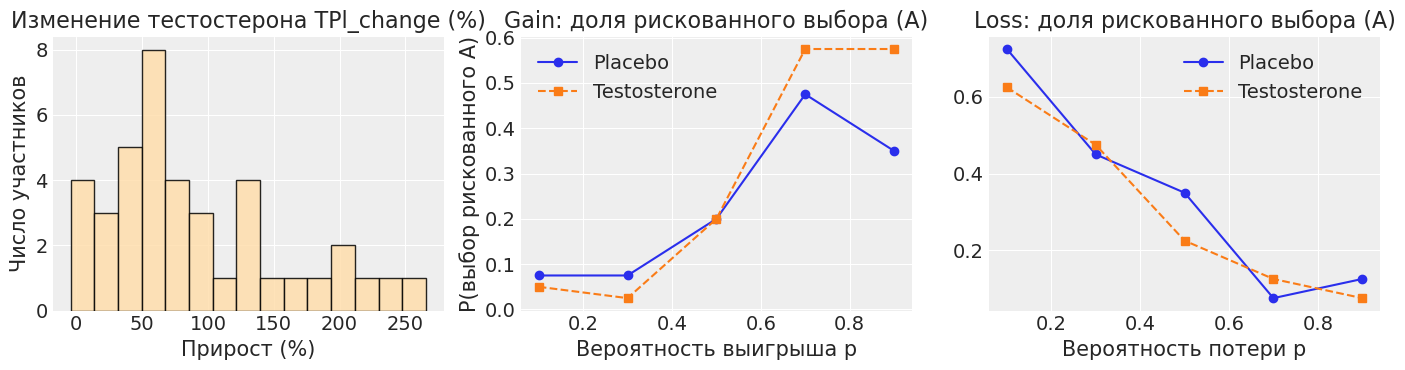

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

# 1. Распределение TPl_change
t_vals = 100 * m_df[m_df["Test"] == 1].groupby("ID")["TPl_change"].mean()
axes[0].hist(t_vals, bins=15, color="navajowhite", edgecolor="k", alpha=0.85)
axes[0].set_title("Изменение тестостерона TPl_change (%)")
axes[0].set_xlabel("Прирост (%)")
axes[0].set_ylabel("Число участников")

# 2. Доля рискованного выбора (Strategy=1) в Gain
for test_val, label, marker in [(0, "Placebo", "o-"), (1, "Testosterone", "s--")]:
    sub = m_df[(m_df["Win"] == 1) & (m_df["Test"] == test_val)].groupby("P")["Strategy"].mean()
    axes[1].plot(sub.index, sub.values, marker, label=label)
axes[1].set_title("Gain: доля рискованного выбора (A)")
axes[1].set_xlabel("Вероятность выигрыша p")
axes[1].set_ylabel("P(выбор рискованного A)")
axes[1].legend()

# 3. Доля рискованного выбора (Strategy=1) в Loss
for test_val, label, marker in [(0, "Placebo", "o-"), (1, "Testosterone", "s--")]:
    sub = m_df[(m_df["Win"] == 0) & (m_df["Test"] == test_val)].groupby("P")["Strategy"].mean()
    axes[2].plot(sub.index, sub.values, marker, label=label)
axes[2].set_title("Loss: доля рискованного выбора (A)")
axes[2].set_xlabel("Вероятность потери p")
axes[2].legend()

plt.tight_layout()
plt.show()


## 2.3. Спецификация моделей и два способа переноса параметров CPT

Обозначим через $\text{Gap}_0$ разницу субъективной ценности рискованного варианта $A$ и гарантированного варианта $B$ (с учётом того, что в пробах с потерями $A, B < 0$):
$$\text{Gap}_0 = v(A, \alpha_{\text{cond}})\, w(p, c_{\text{cond}}) - v(B, \alpha_{\text{cond}}), \qquad \text{Gap} = \operatorname{sign}(\text{Gap}_0)\, \ln\bigl(1 + |\text{Gap}_0|\bigr).$$

Вероятность выбора рискованного варианта $A$ (`Strategy = 1`) моделируется через логит-связь:
$$y_i \sim \operatorname{Bernoulli}(\theta_i), \qquad \operatorname{logit}(\theta_i) = A_i + B_i \cdot \text{Gap}_i,$$
где:
- $A_i$ (`shift`) — базовый сдвиг к рискованному варианту $ (при $\text{Gap} = 0$),
- $B_i$ (`beta`) — чувствительность выбора к субъективному разрыву $\text{Gap}$ (ожидается отрицательной, так как чем выше ценность рискованного варианта $A$ относительно $B$, тем реже выбирают $B$).

В моделях с эффектом тестостерона:
$$A_i = \text{shift}_{\text{cond}} + \text{shift}_{\text{ind}, \text{pid}, \text{cond}} + \delta_{\text{shift}, \text{cond}} \cdot \text{TPl\_change}_i,$$
$$B_i = \text{beta}_{\text{cond}} + \text{beta}_{\text{ind}, \text{pid}, \text{cond}} + \delta_{\text{beta}, \text{cond}} \cdot \text{TPl\_change}_i.$$

Мы сравним 4 последовательные модели:
1. **`model_base_no_test`**: Pooled-модель без тестостерона, $\alpha$ и $c$ **зафиксированы** на средних из Части 1.
2. **`model_base_test`**: Pooled-модель с тестостероном (`TPl_change`), $\alpha$ и $c$ **зафиксированы**.
3. **`model_hier_fixed` (Подход А)**: Иерархическая модель с индивидуальными случайными эффектами (нецентрированная параметризация) и тестостероном, $\alpha$ и $c$ **зафиксированы** на оценках из Части 1.
4. **`model_hier_prior` (Подход Б)**: Иерархическая модель, в которой $\alpha$ и $c$ **не фиксируются точками**, а задаются узкими информативными приорами $\alpha_N \sim \mathcal{N}(\hat{\mu}_{\alpha_N}, \hat{\sigma}_{\alpha_N})$ и $c_N \sim \mathcal{N}(\hat{\mu}_{c_N}, \hat{\sigma}_{c_N})$ из Части 1.


In [13]:
def pt_gap_risk(A, B, p, alpha, c):
    val = pt_value_f(A, alpha) * pt_weights(p, c) - pt_value_f(B, alpha)
    return pt_log1p_signed(val)

coords_risk = {
    "GameType": ["Loss", "Gain"],
    "PId": np.arange(m_df["Inds"].nunique()),
    "obs_id": np.arange(len(m_df)),
}

A_vec = m_df["A"].values.astype(float)
B_vec = m_df["B"].values.astype(float)
P_vec = m_df["P"].values.astype(float)
win_vec = m_df["Win"].values.astype(int)       # 0=Loss, 1=Gain
pid_vec = m_df["Inds"].values.astype(int)
choice_vec = m_df["Strategy"].values.astype(int)
tchange_vec = m_df["TPl_change"].values.astype(float)

# Фиксированные значения из Части 1 (в порядке ["Loss", "Gain"])
alphas_fixed = np.array([alpha_mean["Loss"], alpha_mean["Gain"]])
cs_fixed = np.array([c_mean["Loss"], c_mean["Gain"]])

# Узкие приоры на пробит-шкале из Части 1 (в порядке ["Loss", "Gain"])
alphaN_mu_prior = np.array([alphaN_mean["Loss"], alphaN_mean["Gain"]])
alphaN_sd_prior = np.array([alphaN_sd["Loss"], alphaN_sd["Gain"]])
cN_mu_prior = np.array([cN_mean["Loss"], cN_mean["Gain"]])
cN_sd_prior = np.array([cN_sd["Loss"], cN_sd["Gain"]])


In [14]:
# 1. Pooled без тестостерона
with pm.Model(coords=coords_risk) as model_base_no_test:
    game_type = pm.Data("game_type", win_vec, dims="obs_id")
    choice = pm.Data("choice", choice_vec, dims="obs_id")

    alpha = pt.as_tensor_variable(alphas_fixed)
    c = pt.as_tensor_variable(cs_fixed)
    Gap = pm.Deterministic("Gap", pt_gap_risk(A_vec, B_vec, P_vec, alpha[game_type], c[game_type]), dims="obs_id")

    shift = pm.Normal("shift", mu=0.0, sigma=1.0, dims="GameType")
    beta = pm.Normal("beta", mu=0.5, sigma=0.5, dims="GameType")

    theta = pm.Deterministic("theta", pm.math.invlogit(shift[game_type] + beta[game_type] * Gap), dims="obs_id")
    pm.Bernoulli("Strg", p=theta, observed=choice, dims="obs_id")

# 2. Pooled с тестостероном
with pm.Model(coords=coords_risk) as model_base_test:
    game_type = pm.Data("game_type", win_vec, dims="obs_id")
    Tchange = pm.Data("Tchange", tchange_vec, dims="obs_id")
    choice = pm.Data("choice", choice_vec, dims="obs_id")

    alpha = pt.as_tensor_variable(alphas_fixed)
    c = pt.as_tensor_variable(cs_fixed)
    Gap = pm.Deterministic("Gap", pt_gap_risk(A_vec, B_vec, P_vec, alpha[game_type], c[game_type]), dims="obs_id")

    shift = pm.Normal("shift", mu=0.0, sigma=1.0, dims="GameType")
    beta = pm.Normal("beta", mu=0.5, sigma=0.5, dims="GameType")
    delta_shift = pm.Normal("delta_shift", mu=0.0, sigma=0.5, dims="GameType")
    delta_beta = pm.Normal("delta_beta", mu=0.0, sigma=0.5, dims="GameType")

    A_lin = shift[game_type] + delta_shift[game_type] * Tchange
    B_lin = beta[game_type] + delta_beta[game_type] * Tchange
    theta = pm.Deterministic("theta", pm.math.invlogit(A_lin + B_lin * Gap), dims="obs_id")
    pm.Bernoulli("Strg", p=theta, observed=choice, dims="obs_id")

# 3. Иерархическая модель, Подход А: фиксированные alpha, c
with pm.Model(coords=coords_risk) as model_hier_fixed:
    game_type = pm.Data("game_type", win_vec, dims="obs_id")
    pid = pm.Data("pid", pid_vec, dims="obs_id")
    Tchange = pm.Data("Tchange", tchange_vec, dims="obs_id")
    choice = pm.Data("choice", choice_vec, dims="obs_id")

    alpha = pt.as_tensor_variable(alphas_fixed)
    c = pt.as_tensor_variable(cs_fixed)
    Gap = pm.Deterministic("Gap", pt_gap_risk(A_vec, B_vec, P_vec, alpha[game_type], c[game_type]), dims="obs_id")

    shift = pm.Normal("shift", mu=0.0, sigma=1.0, dims="GameType")
    beta = pm.Normal("beta", mu=0.5, sigma=0.5, dims="GameType")
    delta_shift = pm.Normal("delta_shift", mu=0.0, sigma=0.5, dims="GameType")
    delta_beta = pm.Normal("delta_beta", mu=0.0, sigma=0.5, dims="GameType")

    sigma_shift = pm.Exponential("sigma_shift", 1.0)
    sigma_beta = pm.Exponential("sigma_beta", 1.0)

    z_shift_ind = pm.Normal("z_shift_ind", mu=0.0, sigma=1.0, dims=("PId", "GameType"))
    z_beta_ind = pm.Normal("z_beta_ind", mu=0.0, sigma=1.0, dims=("PId", "GameType"))

    shift_ind = pm.Deterministic("shift_ind", z_shift_ind * sigma_shift, dims=("PId", "GameType"))
    beta_ind = pm.Deterministic("beta_ind", z_beta_ind * sigma_beta, dims=("PId", "GameType"))

    A_lin = shift_ind[pid, game_type] + shift[game_type] + delta_shift[game_type] * Tchange
    B_lin = beta_ind[pid, game_type] + beta[game_type] + delta_beta[game_type] * Tchange
    theta = pm.Deterministic("theta", pm.math.invlogit(A_lin + B_lin * Gap), dims="obs_id")
    pm.Bernoulli("Strg", p=theta, observed=choice, dims="obs_id")

# 4. Иерархическая модель, Подход Б: узкие информативные приоры для alpha, c из Части 1
with pm.Model(coords=coords_risk) as model_hier_prior:
    game_type = pm.Data("game_type", win_vec, dims="obs_id")
    pid = pm.Data("pid", pid_vec, dims="obs_id")
    Tchange = pm.Data("Tchange", tchange_vec, dims="obs_id")
    choice = pm.Data("choice", choice_vec, dims="obs_id")

    alphaN = pm.Normal("alphaN", mu=alphaN_mu_prior, sigma=alphaN_sd_prior, dims="GameType")
    cN = pm.Normal("cN", mu=cN_mu_prior, sigma=cN_sd_prior, dims="GameType")
    alpha = pm.Deterministic("alpha", pt_probit(alphaN), dims="GameType")
    c = pm.Deterministic("c", pt_probit(cN), dims="GameType")

    Gap = pm.Deterministic("Gap", pt_gap_risk(A_vec, B_vec, P_vec, alpha[game_type], c[game_type]), dims="obs_id")

    shift = pm.Normal("shift", mu=0.0, sigma=1.0, dims="GameType")
    beta = pm.Normal("beta", mu=0.5, sigma=0.5, dims="GameType")
    delta_shift = pm.Normal("delta_shift", mu=0.0, sigma=0.5, dims="GameType")
    delta_beta = pm.Normal("delta_beta", mu=0.0, sigma=0.5, dims="GameType")

    sigma_shift = pm.Exponential("sigma_shift", 1.0)
    sigma_beta = pm.Exponential("sigma_beta", 1.0)

    z_shift_ind = pm.Normal("z_shift_ind", mu=0.0, sigma=1.0, dims=("PId", "GameType"))
    z_beta_ind = pm.Normal("z_beta_ind", mu=0.0, sigma=1.0, dims=("PId", "GameType"))

    shift_ind = pm.Deterministic("shift_ind", z_shift_ind * sigma_shift, dims=("PId", "GameType"))
    beta_ind = pm.Deterministic("beta_ind", z_beta_ind * sigma_beta, dims=("PId", "GameType"))

    A_lin = shift_ind[pid, game_type] + shift[game_type] + delta_shift[game_type] * Tchange
    B_lin = beta_ind[pid, game_type] + beta[game_type] + delta_beta[game_type] * Tchange
    theta = pm.Deterministic("theta", pm.math.invlogit(A_lin + B_lin * Gap), dims="obs_id")
    pm.Bernoulli("Strg", p=theta, observed=choice, dims="obs_id")


## 2.4. Prior Predictive Check (до фиттинга)


Sampling: [Strg, alphaN, beta, cN, delta_beta, delta_shift, shift, sigma_beta, sigma_shift, z_beta_ind, z_shift_ind]


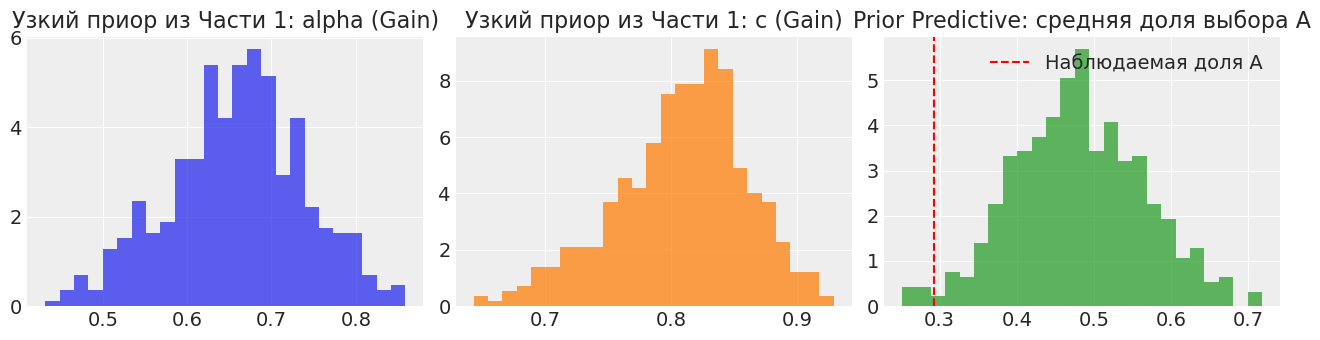

In [15]:
with model_hier_prior:
    prior_risk = pm.sample_prior_predictive(progressbar=False, draws=500, random_seed=RANDOM_SEED)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].hist(prior_risk.prior["alpha"].sel(GameType="Gain").values.ravel(), bins=25, density=True, alpha=0.75)
axes[0].set_title("Узкий приор из Части 1: alpha (Gain)")
axes[1].hist(prior_risk.prior["c"].sel(GameType="Gain").values.ravel(), bins=25, density=True, alpha=0.75, color="tab:orange")
axes[1].set_title("Узкий приор из Части 1: c (Gain)")

prior_risk_mean = prior_risk.prior_predictive["Strg"].mean(dim="obs_id").values.ravel()
axes[2].hist(prior_risk_mean, bins=25, density=True, alpha=0.75, color="tab:green")
axes[2].axvline(m_df["Strategy"].mean(), color="red", linestyle="--", label="Наблюдаемая доля A")
axes[2].set_title("Prior Predictive: средняя доля выбора A")
axes[2].legend()
plt.tight_layout()
plt.show()


## 2.5. Сэмплирование и диагностический шлюз


In [16]:
risk_models = {
    "Base_NoTest": model_base_no_test,
    "Base_Test": model_base_test,
    "Hier_FixedCPT": model_hier_fixed,
    "Hier_PriorCPT": model_hier_prior,
}

idatas_risk = {}
for name, mdl in risk_models.items():
    with mdl:
        idata = pm.sample(
        progressbar=False,
            draws=1000,
            tune=1000,
            chains=4,
            target_accept=0.95,
            random_seed=RANDOM_SEED,
            idata_kwargs={"log_likelihood": True},
        )
        pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=RANDOM_SEED)
    idatas_risk[name] = idata

check_diagnostics(idatas_risk["Base_NoTest"], ["shift", "beta"], "Base_NoTest")
check_diagnostics(idatas_risk["Base_Test"], ["shift", "beta", "delta_shift", "delta_beta"], "Base_Test")
sum_hier_fixed = check_diagnostics(idatas_risk["Hier_FixedCPT"], ["shift", "beta", "delta_shift", "delta_beta", "sigma_shift", "sigma_beta"], "Hier_FixedCPT")
sum_hier_prior = check_diagnostics(idatas_risk["Hier_PriorCPT"], ["shift", "beta", "delta_shift", "delta_beta", "alpha", "c", "sigma_shift", "sigma_beta"], "Hier_PriorCPT")
display(sum_hier_prior.loc[["shift[Loss]", "shift[Gain]", "beta[Loss]", "beta[Gain]", "delta_shift[Loss]", "delta_shift[Gain]", "delta_beta[Loss]", "delta_beta[Gain]"]])


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [shift, beta]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


Sampling: [Strg]


Initializing NUTS using jitter+adapt_diag...


... (12 outputs left out)

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 24 seconds.


Sampling: [Strg]


=== Base_NoTest ===
Divergences: 0 | max R-hat: 1.0041 | min ESS bulk: 3124 | min ESS tail: 2792
=== Base_Test ===
Divergences: 0 | max R-hat: 1.0015 | min ESS bulk: 2195 | min ESS tail: 2009
=== Hier_FixedCPT ===
Divergences: 0 | max R-hat: 1.0017 | min ESS bulk: 1470 | min ESS tail: 2182
=== Hier_PriorCPT ===
Divergences: 0 | max R-hat: 1.0044 | min ESS bulk: 873 | min ESS tail: 749


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
shift[Loss],-1.6,0.37,-2.2,-1,1908,2629,1.00,0.0085,0.0057
shift[Gain],-1,0.53,-1.7,-0.009,872,763,1.00,0.019,0.016
beta[Loss],0.543,0.109,0.38,0.72,1791,2268,1.00,0.0026,0.0016
beta[Gain],0.71,0.23,0.42,1.1,886,748,1.00,0.0088,0.0086
delta_shift[Loss],-0.481,0.307,-0.99,-0.013,3930,3212,1.00,0.0049,0.0046
delta_shift[Gain],0.27,0.27,-0.14,0.71,2568,2146,1.00,0.0054,0.0044
delta_beta[Loss],-0.026,0.084,-0.16,0.11,3483,2841,1.00,0.0014,0.0014
delta_beta[Gain],0.287,0.145,0.064,0.53,3933,2679,1.00,0.0024,0.0024


## 2.6. Targeted PPC и сравнение моделей (PSIS-LOO)

Сравним все 4 модели по PSIS-LOO, а также проверим калибровку предсказаний по 20 уникальным пробам (комбинациям фрейминга, вероятности и условия) и сравним апостериорные оценки эффектов тестостерона между Подходом А (фиксация) и Подходом Б (узкие информативные приоры).


,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Hier_PriorCPT,0,0.0,0.0,NaN,,7 k̂ > 0.70,84.5,-320.0,16.0,1.0
Hier_FixedCPT,1,-6.0,1.9,1.0,,6 k̂ > 0.70,81.6,-320.0,16.0,0.0
Base_Test,2,-90.0,12.0,1.0,,,7.7,-410.0,15.0,0.0
Base_NoTest,3,-90.0,12.0,1.0,,,4.2,-410.0,15.0,0.0


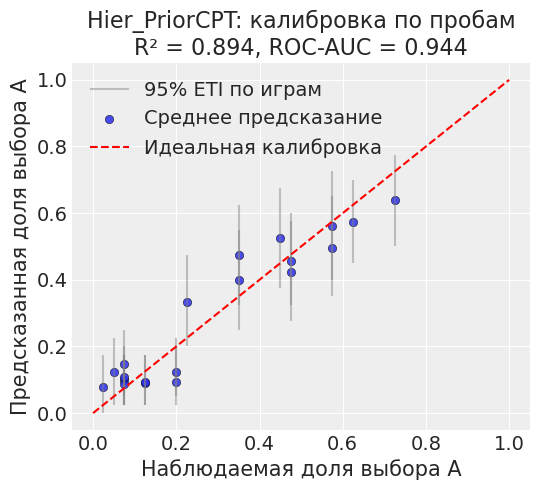

In [17]:
cmp_risk = az.compare(idatas_risk)
display(cmp_risk)

plot_ppc_by_game(idatas_risk["Hier_PriorCPT"], m_df["GameId"].values, m_df["Strategy"].values, "Hier_PriorCPT: калибровка по пробам")


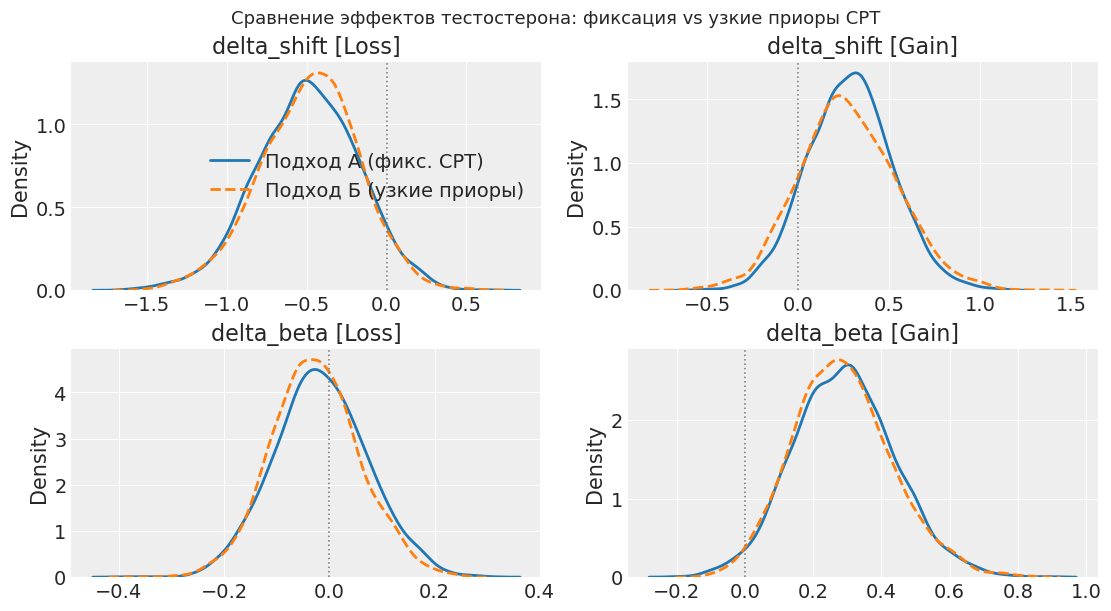

In [18]:
# Сравнение постериоров delta_shift и delta_beta: фиксированные CPT vs узкие информативные приоры
fig, axes = plt.subplots(2, 2, figsize=(11, 6), constrained_layout=True)
for row_idx, param in enumerate(["delta_shift", "delta_beta"]):
    for col_idx, gtype in enumerate(["Loss", "Gain"]):
        ax = axes[row_idx, col_idx]
        s_fixed = idatas_risk["Hier_FixedCPT"].posterior[param].sel(GameType=gtype).values.ravel()
        s_prior = idatas_risk["Hier_PriorCPT"].posterior[param].sel(GameType=gtype).values.ravel()
        sns.kdeplot(s_fixed, ax=ax, color="tab:blue", lw=2, label="Подход А (фикс. CPT)")
        sns.kdeplot(s_prior, ax=ax, color="tab:orange", lw=2, ls="--", label="Подход Б (узкие приоры)")
        ax.axvline(0, color="gray", linestyle=":", lw=1.2)
        ax.set_title(f"{param} [{gtype}]")
        if row_idx == 0 and col_idx == 0:
            ax.legend()
plt.suptitle("Сравнение эффектов тестостерона: фиксация vs узкие приоры CPT", fontsize=13)
plt.show()


## 2.7. Интерпретация на шкале наблюдений: вероятностные контрасты и ROPE

Чтобы оценить практическую значимость эффекта, недостаточно смотреть только на коэффициенты на логит-шкале. Посчитаем:
1. Вероятность направления эффекта $P(\delta > 0)$ и долю апостериорной массы в области практической эквивалентности $\text{ROPE} = [-0.1, 0.1]$.
2. Предсказанные вероятности выбора гарантированного варианта $P(\text{выбор } A)$ в зависимости от субъективной разницы $\text{Gap}$ при трёх уровнях тестостерона: `TPl_change = 0` (плацебо), `0.6` (+60%) и `2.0` (+200%).


In [19]:
post = idatas_risk["Hier_PriorCPT"].posterior
rope_low, rope_high = -0.1, 0.1

rows = []
for param in ["delta_shift", "delta_beta"]:
    for gtype in ["Loss", "Gain"]:
        draws = post[param].sel(GameType=gtype).values.ravel()
        eti = np.percentile(draws, [2.5, 97.5])
        p_pos = float((draws > 0).mean())
        p_rope = float(((draws >= rope_low) & (draws <= rope_high)).mean())
        rows.append({
            "Параметр": f"{param}[{gtype}]",
            "Mean": draws.mean(),
            "SD": draws.std(),
            "95% ETI low": eti[0],
            "95% ETI high": eti[1],
            "P(> 0)": p_pos,
            "P(in ROPE [-0.1, 0.1])": p_rope,
        })
display(pd.DataFrame(rows).round(3))


,Параметр,Mean,SD,95% ETI low,95% ETI high,P(> 0),"P(in ROPE [-0.1, 0.1])"
0,delta_shift[Loss],-0.481,0.307,-1.125,0.097,0.052,0.073
1,delta_shift[Gain],0.273,0.270,-0.231,0.817,0.847,0.182
2,delta_beta[Loss],-0.026,0.084,-0.189,0.144,0.370,0.735
3,delta_beta[Gain],0.287,0.145,0.022,0.597,0.985,0.091


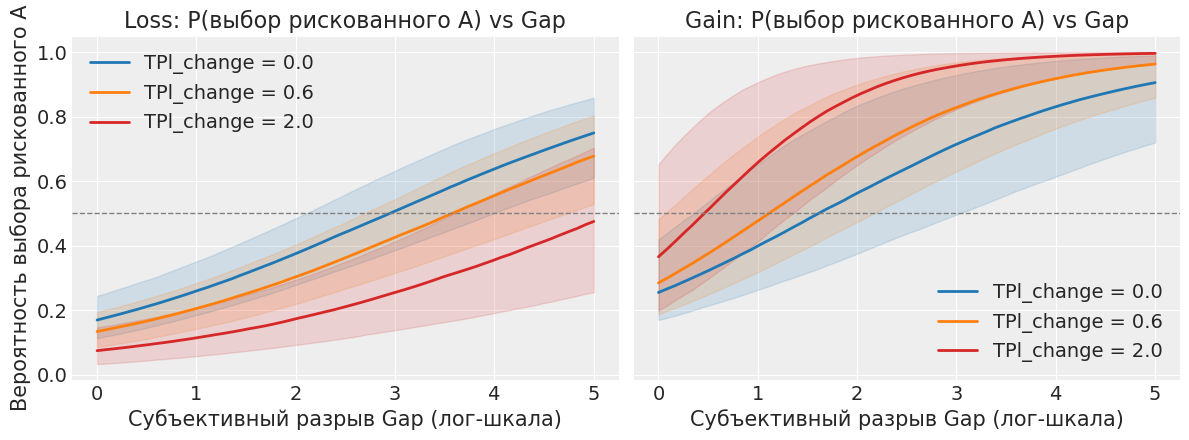

In [20]:
# Кривые чувствительности к субъективному разрыву Gap при разных уровнях TPl_change
gap_grid = np.linspace(0, 5, 60)
test_levels = [0.0, 0.6, 2.0]
colors = ["tab:blue", "tab:orange", "tab:red"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, gtype in zip(axes, ["Loss", "Gain"]):
    sh = post["shift"].sel(GameType=gtype).values.ravel()[:, None]
    be = post["beta"].sel(GameType=gtype).values.ravel()[:, None]
    d_sh = post["delta_shift"].sel(GameType=gtype).values.ravel()[:, None]
    d_be = post["delta_beta"].sel(GameType=gtype).values.ravel()[:, None]

    for t_val, col in zip(test_levels, colors):
        theta_draws = invlogit((sh + d_sh * t_val) + (be + d_be * t_val) * gap_grid[None, :])
        med = np.median(theta_draws, axis=0)
        lo, hi = np.percentile(theta_draws, [10, 90], axis=0)
        ax.plot(gap_grid, med, color=col, lw=2, label=f"TPl_change = {t_val:.1f}")
        ax.fill_between(gap_grid, lo, hi, color=col, alpha=0.15)

    ax.axhline(0.5, color="gray", ls="--", lw=1)
    ax.set_title(f"{gtype}: P(выбор рискованного A) vs Gap")
    ax.set_xlabel("Субъективный разрыв Gap (лог-шкала)")
    ax.legend()

axes[0].set_ylabel("Вероятность выбора рискованного A")
plt.tight_layout()
plt.show()


## 2.8. Model Card и воспроизводимость

| Поле | Описание |
|---|---|
| **Model Name** | `Hier_PriorCPT`: Иерархическая логистическая модель CPT с информативными приорами из внешнего исследования |
| **Research Question** | Как изменение уровня тестостерона (`TPl_change`) влияет на склонность к риску (`delta_shift`, `delta_beta`) при положительном (*Gain*) и отрицательном (*Loss*) фрейминге? |
| **Observational Unit** | Один бинарный выбор участника (`Strategy`: 0 — риск, 1 — гарантированный исход) в задаче фрейминга |
| **Target Population** | Взрослые участники лабораторного эксперимента с двойным слепым введением тестостерона/плацебо |
| **Estimand** | Сдвиг параметров выбора `delta_shift`, `delta_beta` (логит-шкала) и контрасты $P(\text{выбор } A \mid \text{Gap}, \text{TPl\_change})$ |
| **Likelihood & Link** | $y_i \sim \operatorname{Bernoulli}(\theta_i)$, $\operatorname{logit}(\theta_i) = A_i + B_i \cdot \text{Gap}_i$ |
| **Priors** | $\alpha_N, c_N$ — узкие нормальные приоры из апостериорного распределения Части 1 (Nilsson et al., 2011); слабоинформативные приоры для `shift`, `beta`, `delta_*` и $\operatorname{Exponential}(1)$ для $\sigma$ |
| **Hierarchy** | Нецентрированные индивидуальные случайные эффекты `shift_ind`, `beta_ind` по участникам (`PId` $\times$ `GameType`) |
| **Omitted & Limitations** | Импутация пропущенных гормональных замеров для 3 участников (`MR23`, `MR24`, `MR25`); переносимость параметров $\alpha, c$ предполагает сходство функций ценности и взвешивания вероятностей между выборками Nilsson et al. (2011) и текущего эксперимента |


## 2.9. Итоги: помог ли перенос приоров, что хорошо и что плохо

### 1. Помогло ли использование параметров из близкого исследования?
**Да, и подход с узкими приорами (`Hier_PriorCPT`) оказался лучше жёсткой фиксации (`Hier_FixedCPT`).**
- В новом эксперименте всего по 20 бинарных выборов на человека, поэтому оценивать одновременно форму функции ценности ($\alpha$), взвешивание вероятностей ($c$) и гормональные эффекты «с нуля» нецелесообразно — данные не позволят разделить эти параметры.
- Перенос $\alpha$ и $c$ из Части 1 позволил сфокусировать данные эксперимента на сдвиге к риску (`shift`), чувствительности (`beta`) и эффектах тестостерона (`delta_shift`, `delta_beta`).
- По PSIS-LOO модель **`Hier_PriorCPT` заняла 1-е место** (`weight = 1.0`), опередив `Hier_FixedCPT` (`elpd_diff = -6.0 ± 1.9`) и на порядок превзойдя pooled-модели без индивидуальных эффектов (`elpd_diff = -90.0 ± 12.0`). Узкие приоры сохраняют остаточную неопределённость внешнего исследования и дают данным нового эксперимента возможность слегка подстроить $\alpha$ и $c$.

### 2. Что удалось выяснить про эффект тестостерона?
- **Фрейминг выигрыша (Gain):** рост уровня тестостерона (`TPl_change`) **усиливает чувствительность** к субъективному разрыву ценностей (`delta_beta[Gain] = +0.287`, 95% ETI `[0.022, 0.597]`, $P(\delta > 0) = 98.5\%$, в ROPE `[-0.1, 0.1]` попадает только $9.1\%$ массы). То есть под тестостероном участники острее реагируют на преимущество рискованного или гарантированного варианта. Базовый сдвиг `delta_shift[Gain]` положителен в среднем ($+0.273$), но неопределённость велика (95% ETI `[-0.231, 0.817]`, $P(> 0) = 84.7\%$).
- **Фрейминг потери (Loss):** видна тенденция к **снижению базовой склонности к риску** (`delta_shift[Loss] = -0.481`, $94.8\%$ апостериорной массы отрицательны), однако 95% интервал немного пересекает ноль (`[-1.125, 0.097]`), а эффект на чувствительность `delta_beta[Loss]` практически отсутствует (`-0.026`, $73.5\%$ массы в ROPE).

### 3. Что хорошо и что плохо (ограничения)
- **Что хорошо:** все 4 модели Части 2 сошлись чисто (**0 дивергенций**, $\max \hat{R} \le 1.0044$, $\min \text{ESS} \ge 749$), иерархическая структура корректно учла индивидуальный разброс между 40 участниками, а выводы сформулированы на вероятностной шкале выбора, а не только по логит-коэффициентам.
- **Что плохо / ограничения:**
  1. У 3 из 40 участников (`MR23`, `MR24`, `MR25`) гормональные замеры содержали пропуски и были импутированы — это добавляет немоделируемый шум в предиктор `TPl_change`.
  2. У `Hier_PriorCPT` 7 наблюдений (из 800) имеют $\hat{k} > 0.7$ в PSIS-LOO — есть несколько выбросов/случайных нажатий, которые модель описывает хуже (в будущей версии можно добавить параметр случайной ошибки *lapse rate*).
  3. Перенос $\alpha$ и $c$ опирается на предположение, что форма функции ценности и взвешивания вероятностей у участников Nilsson et al. (2011) и в текущем эксперименте достаточно близки.
